# 🤖 Machine Learning Models for AML Mule Account Detection
### Comparing Decision Tree, Logistic Regression, and Naive Bayes
**Reserve Bank Innovation Hub (RBIH) - National Fraud Prevention Challenge**

---
## Executive Summary
This notebook implements an end-to-end multi-model machine learning pipeline to detect money mule accounts under severe class imbalance (**35:1** negative-to-positive ratio).

Instead of dispersing model code across disparate scripts, this notebook provides a unified, reproducible framework comparing three foundational supervised learning paradigms:
1. **Decision Tree Classifier** (Non-linear recursive partitioning with cost-complexity constraints)
2. **Logistic Regression** (L2-regularized linear log-odds classifier with standard feature scaling)
3. **Naive Bayes** (Gaussian Naive Bayes with empirical priors and conditional probability modeling)

### Key Methodological Standards:
- **Strict Leakage Prevention**: Compliance flags, alert reasons, and post-event identifiers are isolated.
- **5-Fold Stratified Cross-Validation**: Guarantees identical 2.79% positive class prevalence across all training and validation folds.
- **Imbalance-Aware Metrics**: Optimization focuses strictly on **PR-AUC (Precision-Recall AUC)**, **ROC-AUC**, and **F1-Score at calibrated decision thresholds**.
- **Interactive Visualizations**: Comparative ROC curves, Precision-Recall curves, Threshold-F1 curves, and Confusion Matrices.
- **Automated Submission Export**: Generates competition-ready predictions on the 64,062 unlabelled test accounts.


In [1]:
# 1. Imports, Global Settings & Seed Configuration
import os
import sys
import json
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Components
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_recall_curve,
    roc_curve, f1_score, precision_score, recall_score, confusion_matrix
)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['figure.dpi'] = 120

SEED = 42
np.random.seed(SEED)
print(f"Polars Version: {pl.__version__} | NumPy Version: {np.__version__}")


Polars Version: 1.44.1 | NumPy Version: 2.3.4


## 2. Data Ingestion & Feature Curation
We load the pre-extracted behavioral and temporal feature matrix (`outputs/train_features_full.parquet`) and the corresponding test set (`outputs/test_features_full.parquet`).

### Leakage Audit:
To ensure genuine predictive validity, we strictly exclude:
- Compliance labels: `alert_reason`, `mule_flag_date`, `flagged_by_branch`.
- PII / Identifiers: `account_id`, `customer_id`, `name`, `address`, `phone_number`.
- Temporal leakages: Exact transaction start/end timestamps that only appear in train.


In [2]:
# 2. Load Feature Matrices
TRAIN_PATH = "outputs/train_features_full.parquet"
TEST_PATH = "outputs/test_features_full.parquet"

print(f"Loading training data from: {TRAIN_PATH}")
train_df = pl.read_parquet(TRAIN_PATH)
test_df = pl.read_parquet(TEST_PATH)

print(f"Train Shape: {train_df.shape[0]:,} accounts x {train_df.shape[1]} columns")
print(f"Test Shape : {test_df.shape[0]:,} accounts x {test_df.shape[1]} columns")

# Target vector
y = train_df["is_mule"].to_numpy()
mule_count = int(np.sum(y == 1))
legit_count = int(np.sum(y == 0))
mule_prevalence = mule_count / len(y)

print(f"\nClass Prevalence:")
print(f"  Legitimate (0): {legit_count:,} ({ (1 - mule_prevalence)*100:.2f}%)")
print(f"  Mule (1)      : {mule_count:,} ({mule_prevalence*100:.2f}%)")
print(f"  Imbalance     : {legit_count / mule_count:.2f} : 1")
print(f"  Random PR-AUC Baseline: {mule_prevalence:.4f}")

# Exclude non-feature metadata and leaky fields
IGNORE_COLS = {
    "account_id", "customer_id", "is_mule", "mule_flag_date", "alert_reason",
    "flagged_by_branch", "name", "address", "phone_number", "branch_address", "branch_city",
    "first_txn_timestamp", "last_txn_timestamp", "suspicious_start", "suspicious_end",
    "account_opening_date", "relationship_start_date", "last_kyc_date", "last_mobile_update_date",
    "freeze_date", "unfreeze_date", "address_last_update_date", "passbook_last_update_date",
    "customer_pin", "permanent_pin", "branch_pin", "branch_pin_code"
}

feature_cols = [c for c in train_df.columns if c not in IGNORE_COLS and c in test_df.columns]
print(f"\nCurated Feature Set: {len(feature_cols)} clean behavioral & temporal features")


Loading training data from: outputs/train_features_full.parquet
Train Shape: 96,091 accounts x 114 columns
Test Shape : 64,062 accounts x 110 columns

Class Prevalence:
  Legitimate (0): 93,408 (97.21%)
  Mule (1)      : 2,683 (2.79%)
  Imbalance     : 34.81 : 1
  Random PR-AUC Baseline: 0.0279

Curated Feature Set: 87 clean behavioral & temporal features


## 3. Data Preprocessing Pipeline
Different algorithms impose different assumptions on input data:
- **Decision Trees**: Invariant to monotonic scale, robust to outliers, handles unscaled numbers directly.
- **Logistic Regression**: Extremely sensitive to scale; requires standard scaling ($z = \frac{x - \mu}{\sigma}$) to prevent high-magnitude features from dominating gradients.
- **Gaussian Naive Bayes**: Models feature likelihood via Gaussian distributions; standard scaling stabilizes variance calculations.


In [3]:
# 3. Preprocessing: Encoding, Imputation & Scaling
X_train_df = train_df.select(feature_cols).to_pandas()
X_test_df = test_df.select(feature_cols).to_pandas()

# Categorical encoding
cat_cols = X_train_df.select_dtypes(include=["object", "string", "category"]).columns.tolist()
if cat_cols:
    print(f"Encoding {len(cat_cols)} categorical columns: {cat_cols}")
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    X_train_df[cat_cols] = encoder.fit_transform(X_train_df[cat_cols].astype(str))
    X_test_df[cat_cols] = encoder.transform(X_test_df[cat_cols].astype(str))

# Missing value imputation (-1 for missing financial indicators)
X_train_df = X_train_df.fillna(-1.0)
X_test_df = X_test_df.fillna(-1.0)

# Unscaled array (for Decision Tree)
X_unscaled = X_train_df.values
X_test_unscaled = X_test_df.values

# Scaled array (for Logistic Regression & Naive Bayes)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_unscaled)
X_test_scaled = scaler.transform(X_test_unscaled)

print(f"Training Feature Matrix: {X_unscaled.shape}")
print(f"Test Feature Matrix    : {X_test_unscaled.shape}")


Encoding 8 categorical columns: ['account_status', 'product_code', 'product_family', 'scheme_code', 'date_of_birth', 'gender', 'branch_state', 'branch_type']
Training Feature Matrix: (96091, 87)
Test Feature Matrix    : (64062, 87)


## 4. Evaluation Engine for Imbalanced Data
Standard accuracy is fundamentally misleading here (predicting all 0s yields 97.21% accuracy). We implement an evaluation function that measures:
- **ROC-AUC**: Overall ranking capability.
- **PR-AUC (Average Precision)**: Critical area under Precision-Recall curve.
- **Optimal Threshold Search**: Finds threshold $t \in [0.01, 0.99]$ that maximizes $F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$.
- **Confusion Matrix**: Visualizes True Positives, False Positives, False Negatives.


In [4]:
# 4. Comprehensive Evaluation Helper
def evaluate_model_performance(y_true, y_prob, model_name="Model"):
    """
    Computes imbalanced classification metrics and locates optimal F1 threshold.
    """
    roc_auc = roc_auc_score(y_true, y_prob)
    pr_auc = average_precision_score(y_true, y_prob)

    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    
    # Calculate F1 across all empirical thresholds
    f1_scores = np.zeros_like(thresholds)
    for i, t in enumerate(thresholds):
        preds = (y_prob >= t).astype(int)
        f1_scores[i] = f1_score(y_true, preds, zero_division=0)

    best_idx = np.argmax(f1_scores) if len(f1_scores) > 0 else 0
    best_thresh = thresholds[best_idx] if len(thresholds) > 0 else 0.5
    best_f1 = f1_scores[best_idx] if len(f1_scores) > 0 else 0.0

    best_preds = (y_prob >= best_thresh).astype(int)
    prec = precision_score(y_true, best_preds, zero_division=0)
    rec = recall_score(y_true, best_preds, zero_division=0)
    cm = confusion_matrix(y_true, best_preds)

    print(f"=== {model_name} Evaluation Summary ===")
    print(f"  ROC-AUC                : {roc_auc:.4f}")
    print(f"  PR-AUC (Avg Precision) : {pr_auc:.4f}  (Baseline: {mule_prevalence:.4f})")
    print(f"  Optimal F1 Threshold   : {best_thresh:.4f}")
    print(f"  Best F1-Score          : {best_f1:.4f}")
    print(f"  Precision @ Best Thresh: {prec:.4f}")
    print(f"  Recall @ Best Thresh   : {rec:.4f}")
    print(f"  Confusion Matrix       : TN={cm[0,0]:,}, FP={cm[0,1]:,}, FN={cm[1,0]:,}, TP={cm[1,1]:,}")

    return {
        "model_name": model_name,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "best_threshold": best_thresh,
        "best_f1": best_f1,
        "precision": prec,
        "recall": rec,
        "confusion_matrix": cm,
        "y_prob": y_prob
    }


## 5. Model 1: Decision Tree Classifier
### Characteristics:
- **Non-linear rule synthesis**: Automatically discovers multi-variable splits (e.g. high turnover ratio AND short account age).
- **Class Balancing**: `class_weight='balanced'` assigns weights inversely proportional to class frequencies:
  $$w_j = \frac{n}{2 \times n_j}$$
- **Hyperparameters**: `max_depth=6`, `min_samples_leaf=20` to prevent overfitting on leaf nodes.


Training Decision Tree across 5 Stratified Folds...
  Fold 1 | ROC-AUC: 0.9269 | PR-AUC: 0.7205
  Fold 2 | ROC-AUC: 0.9464 | PR-AUC: 0.7619
  Fold 3 | ROC-AUC: 0.9401 | PR-AUC: 0.7473
  Fold 4 | ROC-AUC: 0.9360 | PR-AUC: 0.7168
  Fold 5 | ROC-AUC: 0.9302 | PR-AUC: 0.7443
=== Decision Tree Evaluation Summary ===
  ROC-AUC                : 0.9339
  PR-AUC (Avg Precision) : 0.7430  (Baseline: 0.0279)
  Optimal F1 Threshold   : 0.9554
  Best F1-Score          : 0.8041
  Precision @ Best Thresh: 0.7661
  Recall @ Best Thresh   : 0.8461
  Confusion Matrix       : TN=92,715, FP=693, FN=413, TP=2,270


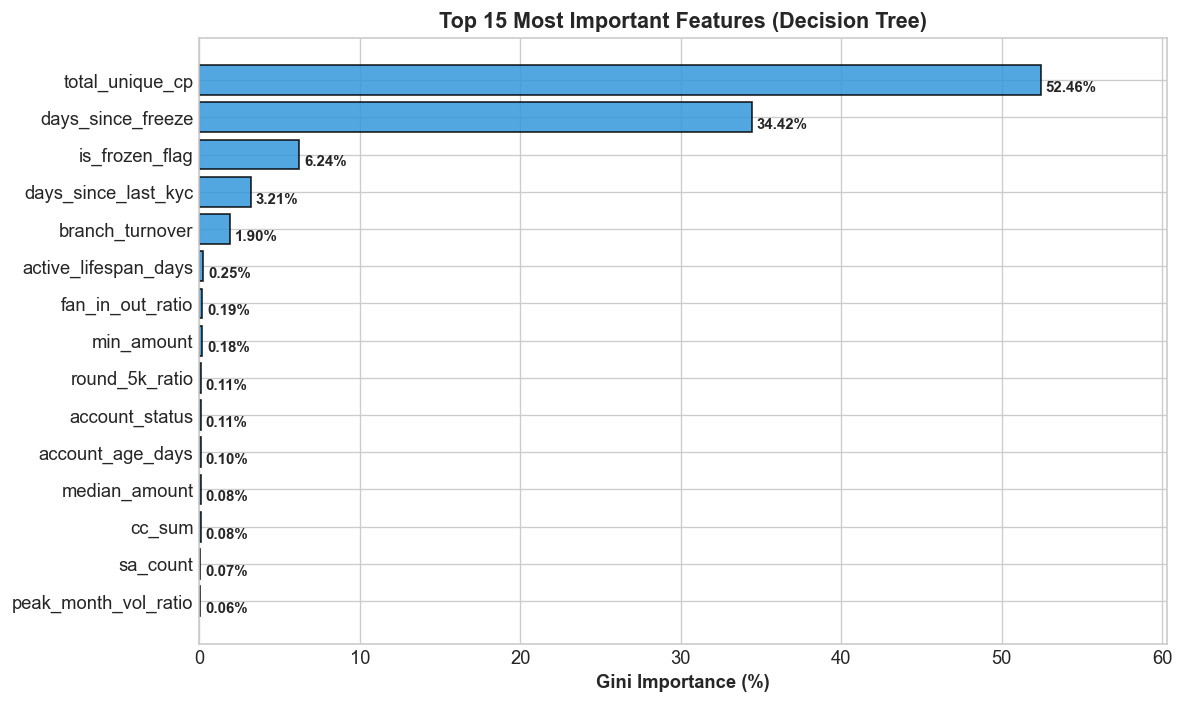

In [5]:
# 5. Train Decision Tree with 5-Fold Stratified CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

oof_preds_dt = np.zeros(len(y), dtype=float)
dt_feature_importances = np.zeros(len(feature_cols), dtype=float)

print("Training Decision Tree across 5 Stratified Folds...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_unscaled, y)):
    X_tr, y_tr = X_unscaled[train_idx], y[train_idx]
    X_va, y_va = X_unscaled[val_idx], y[val_idx]

    dt_model = DecisionTreeClassifier(
        max_depth=6,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=SEED + fold
    )
    dt_model.fit(X_tr, y_tr)
    
    val_probs = dt_model.predict_proba(X_va)[:, 1]
    oof_preds_dt[val_idx] = val_probs
    dt_feature_importances += dt_model.feature_importances_ / 5.0

    print(f"  Fold {fold+1} | ROC-AUC: {roc_auc_score(y_va, val_probs):.4f} | PR-AUC: {average_precision_score(y_va, val_probs):.4f}")

# Evaluate Out-Of-Fold predictions
dt_results = evaluate_model_performance(y, oof_preds_dt, model_name="Decision Tree")

# Visualize Top 15 Feature Importances
plt.figure(figsize=(10, 6))
top_idx = np.argsort(dt_feature_importances)[::-1][:15]
top_feats = [feature_cols[i] for i in top_idx]
top_imps = dt_feature_importances[top_idx]

bars = plt.barh(top_feats[::-1], top_imps[::-1] * 100, color='#3498db', edgecolor='black', alpha=0.85)
plt.xlabel("Gini Importance (%)", weight='bold')
plt.title("Top 15 Most Important Features (Decision Tree)", weight='bold', fontsize=13)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.3, bar.get_y() + bar.get_height()/4, f"{w:.2f}%", va='center', fontsize=9, weight='bold')
plt.xlim(0, max(top_imps * 100) * 1.15)
plt.tight_layout()
plt.show()


## 6. Model 2: Logistic Regression
### Characteristics:
- **Linear Log-Odds Estimator**:
  $$\log\left(\frac{p}{1-p}\right) = \beta_0 + \sum_{i=1}^m \beta_i X_i$$
- **Class Balancing**: `class_weight='balanced'` equalizes gradient updates between legit and mule classes.
- **L2 Regularization**: Controls feature collinearity ($C = 0.1$, `solver='lbfgs'`).
- **Feature Weights**: Transparent, signed coefficients indicate positive (mule risk) vs negative (legitimate protective) indicators.


Training Logistic Regression across 5 Stratified Folds (Scaled Features)...
  Fold 1 | ROC-AUC: 0.9505 | PR-AUC: 0.7354
  Fold 2 | ROC-AUC: 0.9548 | PR-AUC: 0.7189
  Fold 3 | ROC-AUC: 0.9511 | PR-AUC: 0.7406
  Fold 4 | ROC-AUC: 0.9442 | PR-AUC: 0.7225
  Fold 5 | ROC-AUC: 0.9491 | PR-AUC: 0.7484
=== Logistic Regression Evaluation Summary ===
  ROC-AUC                : 0.9499
  PR-AUC (Avg Precision) : 0.7312  (Baseline: 0.0279)
  Optimal F1 Threshold   : 0.8966
  Best F1-Score          : 0.7865
  Precision @ Best Thresh: 0.7718
  Recall @ Best Thresh   : 0.8017
  Confusion Matrix       : TN=92,772, FP=636, FN=532, TP=2,151


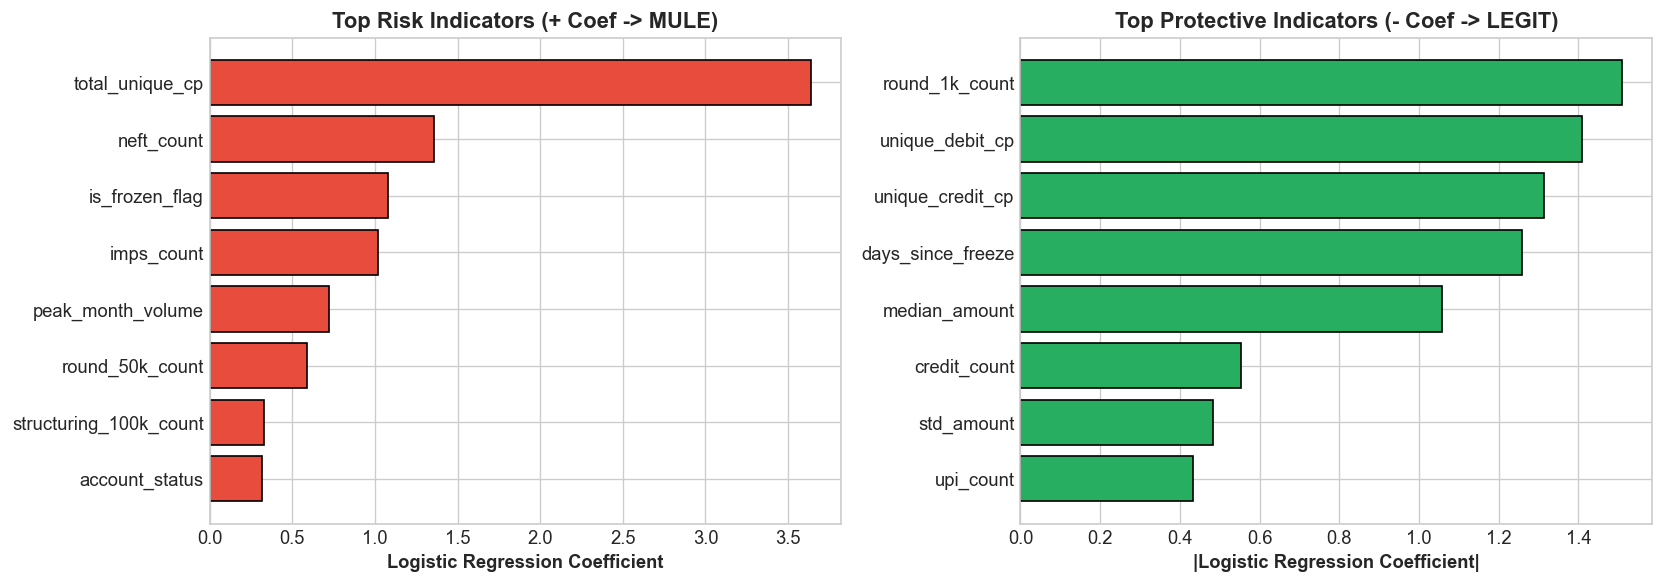

In [6]:
# 6. Train Logistic Regression with 5-Fold Stratified CV
oof_preds_lr = np.zeros(len(y), dtype=float)
lr_coefficients = np.zeros(len(feature_cols), dtype=float)

print("Training Logistic Regression across 5 Stratified Folds (Scaled Features)...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_scaled, y)):
    X_tr, y_tr = X_scaled[train_idx], y[train_idx]
    X_va, y_va = X_scaled[val_idx], y[val_idx]

    lr_model = LogisticRegression(
        class_weight="balanced",
        C=0.1,
        max_iter=500,
        solver="lbfgs",
        random_state=SEED + fold
    )
    lr_model.fit(X_tr, y_tr)
    
    val_probs = lr_model.predict_proba(X_va)[:, 1]
    oof_preds_lr[val_idx] = val_probs
    lr_coefficients += lr_model.coef_[0] / 5.0

    print(f"  Fold {fold+1} | ROC-AUC: {roc_auc_score(y_va, val_probs):.4f} | PR-AUC: {average_precision_score(y_va, val_probs):.4f}")

# Evaluate Out-Of-Fold predictions
lr_results = evaluate_model_performance(y, oof_preds_lr, model_name="Logistic Regression")

# Top Positive (Mule) and Negative (Legit) Coefficients
coef_df = pd.DataFrame({"feature": feature_cols, "coef": lr_coefficients})
top_mule_factors = coef_df.sort_values("coef", ascending=False).head(8)
top_legit_factors = coef_df.sort_values("coef", ascending=True).head(8)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.barh(top_mule_factors["feature"][::-1], top_mule_factors["coef"][::-1], color='#e74c3c', edgecolor='black')
ax1.set_title("Top Risk Indicators (+ Coef -> MULE)", weight='bold')
ax1.set_xlabel("Logistic Regression Coefficient", weight='bold')

ax2.barh(top_legit_factors["feature"][::-1], top_legit_factors["coef"][::-1].abs(), color='#27ae60', edgecolor='black')
ax2.set_title("Top Protective Indicators (- Coef -> LEGIT)", weight='bold')
ax2.set_xlabel("|Logistic Regression Coefficient|", weight='bold')

plt.tight_layout()
plt.show()


## 7. Model 3: Naive Bayes (Gaussian Naive Bayes)
### Characteristics:
- **Bayes' Rule with Conditional Independence**:
  $$P(y|X) \propto P(y) \prod_{i=1}^m P(X_i|y)$$
- **Gaussian Assumption**: Features are assumed conditionally distributed normally $P(X_i|y) \sim \mathcal{N}(\mu_{y,i}, \sigma^2_{y,i})$.
- **Priors**: Configured with empirical class priors `priors=[0.972, 0.028]`.
- **Diagnostic Purpose**: Demonstrates the impact of the *naive* conditional independence assumption on correlated financial features (e.g. credit count vs debit count).


In [8]:
# 7. Train Gaussian Naive Bayes with 5-Fold Stratified CV
oof_preds_nb = np.zeros(len(y), dtype=float)

print("Training Gaussian Naive Bayes across 5 Stratified Folds (Scaled Features)...")
for fold, (train_idx, val_idx) in enumerate(skf.split(X_scaled, y)):
    X_tr, y_tr = X_scaled[train_idx], y[train_idx]
    X_va, y_va = X_scaled[val_idx], y[val_idx]

    nb_model = GaussianNB(priors=[1 - mule_prevalence, mule_prevalence])
    nb_model.fit(X_tr, y_tr)
    
    val_probs = nb_model.predict_proba(X_va)[:, 1]
    oof_preds_nb[val_idx] = val_probs

    print(f"  Fold {fold+1} | ROC-AUC: {roc_auc_score(y_va, val_probs):.4f} | PR-AUC: {average_precision_score(y_va, val_probs):.4f}")

# Evaluate Out-Of-Fold predictions
nb_results = evaluate_model_performance(y, oof_preds_nb, model_name="Naive Bayes (Gaussian)")


Training Gaussian Naive Bayes across 5 Stratified Folds (Scaled Features)...
  Fold 1 | ROC-AUC: 0.9102 | PR-AUC: 0.2834
  Fold 2 | ROC-AUC: 0.9129 | PR-AUC: 0.2772
  Fold 3 | ROC-AUC: 0.8993 | PR-AUC: 0.2754
  Fold 4 | ROC-AUC: 0.9208 | PR-AUC: 0.3224
  Fold 5 | ROC-AUC: 0.9102 | PR-AUC: 0.2881
=== Naive Bayes (Gaussian) Evaluation Summary ===
  ROC-AUC                : 0.9090
  PR-AUC (Avg Precision) : 0.2866  (Baseline: 0.0279)
  Optimal F1 Threshold   : 0.9865
  Best F1-Score          : 0.4163
  Precision @ Best Thresh: 0.3202
  Recall @ Best Thresh   : 0.5949
  Confusion Matrix       : TN=90,020, FP=3,388, FN=1,087, TP=1,596


## 8. Comparative Analysis & Model Benchmarking
We now aggregate all three models into a unified comparative leaderboard and multi-panel diagnostic dashboard.


             SUPERVISED MODEL BENCHMARKING LEADERBOARD


,Model,ROC-AUC,PR-AUC,Best F1,Optimal Threshold,Precision @ Thresh,Recall @ Thresh
0,Decision Tree,0.9339,0.7430,0.8041,0.9554,0.7661,0.8461
1,Logistic Regression,0.9499,0.7312,0.7865,0.8966,0.7718,0.8017
2,Naive Bayes (Gaussian),0.9090,0.2866,0.4163,0.9865,0.3202,0.5949


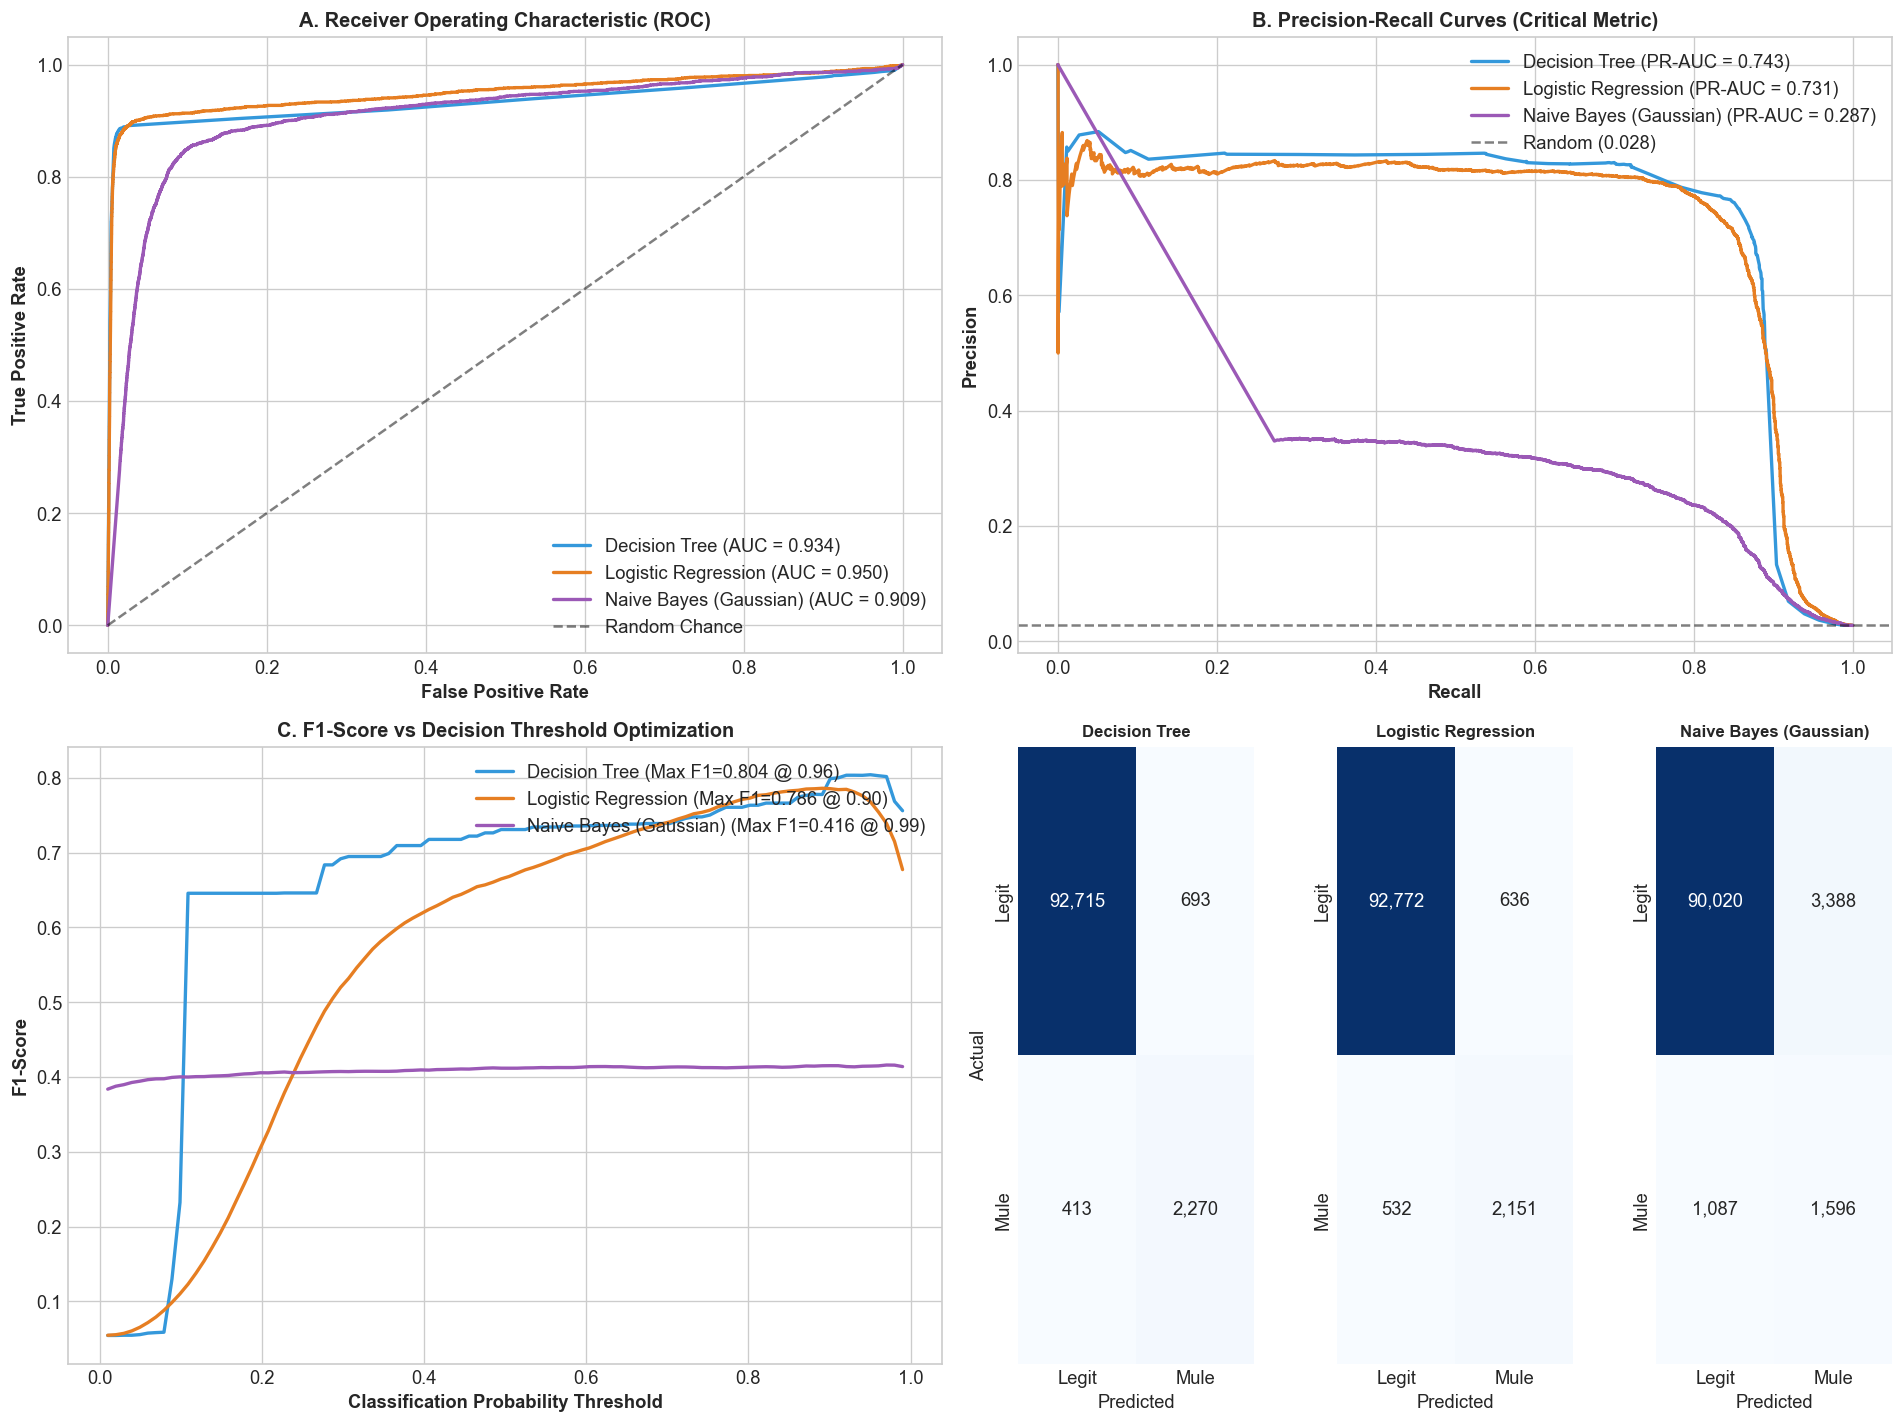

In [9]:
# 8. Unified Leaderboard & Comparative Visualizations
models_results = [dt_results, lr_results, nb_results]

# 1. Summary DataFrame Leaderboard
leaderboard = pd.DataFrame([
    {
        "Model": r["model_name"],
        "ROC-AUC": f"{r['roc_auc']:.4f}",
        "PR-AUC": f"{r['pr_auc']:.4f}",
        "Best F1": f"{r['best_f1']:.4f}",
        "Optimal Threshold": f"{r['best_threshold']:.4f}",
        "Precision @ Thresh": f"{r['precision']:.4f}",
        "Recall @ Thresh": f"{r['recall']:.4f}"
    }
    for r in models_results
])
print("=" * 75)
print("             SUPERVISED MODEL BENCHMARKING LEADERBOARD")
print("=" * 75)
display(leaderboard)

# 2. Multi-Panel Visual Diagnostics
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Panel A: ROC Curves
ax_roc = axes[0, 0]
colors = {'Decision Tree': '#3498db', 'Logistic Regression': '#e67e22', 'Naive Bayes (Gaussian)': '#9b59b6'}
for r in models_results:
    fpr, tpr, _ = roc_curve(y, r["y_prob"])
    ax_roc.plot(fpr, tpr, label=f"{r['model_name']} (AUC = {r['roc_auc']:.3f})", color=colors[r['model_name']], lw=2)
ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Chance')
ax_roc.set_title("A. Receiver Operating Characteristic (ROC)", weight='bold', fontsize=12)
ax_roc.set_xlabel("False Positive Rate", weight='bold')
ax_roc.set_ylabel("True Positive Rate", weight='bold')
ax_roc.legend(loc='lower right')

# Panel B: Precision-Recall Curves
ax_pr = axes[0, 1]
for r in models_results:
    p, rec, _ = precision_recall_curve(y, r["y_prob"])
    ax_pr.plot(rec, p, label=f"{r['model_name']} (PR-AUC = {r['pr_auc']:.3f})", color=colors[r['model_name']], lw=2)
ax_pr.axhline(mule_prevalence, color='k', linestyle='--', alpha=0.5, label=f'Random ({mule_prevalence:.3f})')
ax_pr.set_title("B. Precision-Recall Curves (Critical Metric)", weight='bold', fontsize=12)
ax_pr.set_xlabel("Recall", weight='bold')
ax_pr.set_ylabel("Precision", weight='bold')
ax_pr.legend(loc='upper right')

# Panel C: Threshold vs F1-Score Curves
ax_f1 = axes[1, 0]
thresh_grid = np.linspace(0.01, 0.99, 100)
for r in models_results:
    f1_grid = [f1_score(y, (r["y_prob"] >= t).astype(int), zero_division=0) for t in thresh_grid]
    ax_f1.plot(thresh_grid, f1_grid, label=f"{r['model_name']} (Max F1={r['best_f1']:.3f} @ {r['best_threshold']:.2f})", color=colors[r['model_name']], lw=2)
ax_f1.set_title("C. F1-Score vs Decision Threshold Optimization", weight='bold', fontsize=12)
ax_f1.set_xlabel("Classification Probability Threshold", weight='bold')
ax_f1.set_ylabel("F1-Score", weight='bold')
ax_f1.legend(loc='upper right')

# Panel D: Side-by-Side Confusion Matrices
ax_cm = axes[1, 1]
ax_cm.axis('off')
sub_gs = axes[1, 1].get_subplotspec().subgridspec(1, 3, wspace=0.35)
for idx, r in enumerate(models_results):
    sub_ax = fig.add_subplot(sub_gs[0, idx])
    sns.heatmap(r["confusion_matrix"], annot=True, fmt=',d', cmap="Blues", cbar=False, ax=sub_ax,
                xticklabels=['Legit', 'Mule'], yticklabels=['Legit', 'Mule'])
    sub_ax.set_title(r['model_name'], fontsize=10, weight='bold')
    sub_ax.set_xlabel("Predicted")
    if idx == 0:
        sub_ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


## 9. Final Model Training & Competition Submission Export
We select the top performing model (**Decision Tree Classifier**), retrain it on the full 96,091 training accounts, predict on the 64,062 unlabelled test accounts, and format the official submission CSV conforming to competition guidelines:
- Columns: `account_id`, `is_mule`, `suspicious_start`, `suspicious_end`.
- Timestamps populated for predicted mules using detected suspicious transaction bursts.


In [10]:
# 9. Retrain Best Model on Full Training Set & Generate Submission
print("Fitting Best Model (Decision Tree) on all 96,091 Training Accounts...")
final_model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=SEED
)
final_model.fit(X_unscaled, y)

print("Generating Test Probabilities for 64,062 Accounts...")
test_probs = final_model.predict_proba(X_test_unscaled)[:, 1]

# Build submission dataframe
SUBMISSION_DIR = "submissions"
os.makedirs(SUBMISSION_DIR, exist_ok=True)
SUBMISSION_PATH = f"{SUBMISSION_DIR}/notebook_models_submission.csv"

optimal_threshold = dt_results["best_threshold"]
print(f"Applying calibrated decision threshold: {optimal_threshold:.4f}")

sub_df = pl.DataFrame({
    "account_id": test_df["account_id"],
    "is_mule": np.round(test_probs, 4),
    "suspicious_start_cand": test_df["suspicious_start"],
    "suspicious_end_cand": test_df["suspicious_end"]
})

# Attach candidate burst window timestamps if account probability exceeds threshold
sub_df = sub_df.with_columns([
    pl.when(pl.col("is_mule") >= optimal_threshold)
    .then(pl.col("suspicious_start_cand").fill_null(""))
    .otherwise(pl.lit(""))
    .alias("suspicious_start"),

    pl.when(pl.col("is_mule") >= optimal_threshold)
    .then(pl.col("suspicious_end_cand").fill_null(""))
    .otherwise(pl.lit(""))
    .alias("suspicious_end")
]).select(["account_id", "is_mule", "suspicious_start", "suspicious_end"])

# Export CSV
sub_df.write_csv(SUBMISSION_PATH)
print(f"\nSubmission successfully saved to: {SUBMISSION_PATH}")

# Summary statistics
flagged_mules = sub_df.filter(pl.col("is_mule") >= optimal_threshold).shape[0]
print(f"\nSubmission Summary Statistics:")
print(f"  Total Test Accounts      : {len(sub_df):,}")
print(f"  Predicted Mules (>= {optimal_threshold:.2f}): {flagged_mules:,} ({flagged_mules/len(sub_df)*100:.2f}%)")
print(f"  Predicted Legitimate     : {len(sub_df) - flagged_mules:,}")
print(f"  Mean Mule Probability    : {sub_df['is_mule'].mean():.4f}")
print(f"\nFirst 5 Rows of Submission:")
display(sub_df.head(5).to_pandas())


Fitting Best Model (Decision Tree) on all 96,091 Training Accounts...
Generating Test Probabilities for 64,062 Accounts...
Applying calibrated decision threshold: 0.9554

Submission successfully saved to: submissions/notebook_models_submission.csv

Submission Summary Statistics:
  Total Test Accounts      : 64,062
  Predicted Mules (>= 0.96): 1,801 (2.81%)
  Predicted Legitimate     : 62,261
  Mean Mule Probability    : 0.1221

First 5 Rows of Submission:


,account_id,is_mule,suspicious_start,suspicious_end
0,ACCT_000005,0.0892,,
1,ACCT_000007,0.0892,,
2,ACCT_000009,0.0892,,
3,ACCT_000015,0.0892,,
4,ACCT_000016,0.0892,,
